# Single-column response and basal boundaries

This tutorial compares efficient and restricted basal drainage for the same soil column. It first applies 4.5 mm/h for 24 h, then repeats the calculation with two rainfall peaks and the same 108 mm total. We inspect basal flux, estimated water-table rise, and factor of safety (FS), followed by their variation with depth.

The setup is inspired by the Qtb material in Baum et al. (2010), with an independently specified initial water-table depth. For reproduction of the published Qva/Qtb profiles, use the [space-time verification notebook](/unsatstab/verification/03_baum_etal_space_time/).

This tutorial explicitly selects `equation_set="baum_etal"` as its comparison baseline. The package default is `"srivastava_yeh"`. To explore that formulation, change this one setting and rerun every calculation; pressure, water content, and stability on a slope can change. See the [equation comparison](/unsatstab/fundamentals/#pressure-and-water-content-equation-sets).


## Model setup

The column extends to 1.00 m. The initial water table and selected observation plane coincide with that base. Initial pressure head at that plane is zero; any estimated water-table rise places the plane below the water table. All FS time series evaluate that selected plane, not the minimum over the whole depth profile.

| Quantity | Value |
| --- | ---: |
| Slope angle, $\delta$ | 40° |
| Maximum column depth, $z_{\mathrm{max}}$ | 1.00 m |
| Selected-plane depth, $z_{\mathrm{f}}$ | 1.00 m |
| Initial water-table depth, $z_{\mathrm{w},0}$ | 1.00 m |
| Saturated conductivity, $K_{\mathrm{s}}$ | 36 mm/h |
| Intrinsic Gardner parameter, $\alpha$ | 3 m⁻¹ |
| Saturated/residual water content, $\theta_{\mathrm{s}}$, $\theta_{\mathrm{r}}$ | 0.41, 0.06 m³/m³ |
| Background infiltration, $I_{\mathrm{ZLT}}$ | 0.54 mm/h |
| Effective cohesion, $c'$ | 3000 Pa |
| Effective friction angle, $\phi'$ | 33.6° |
| Soil unit weight, $\gamma$ | 18 000 N/m³ |

`InfiniteDrainageBoundary` uses drainage efficiency $\eta=1$, giving a capacity of about 14.87 mm/h here. `FinitePerchedBoundary` defaults to $\eta=0.1$, giving about 1.487 mm/h. Efficiency multiplies a capacity, not the fraction of rainfall drained. Neither setting imposes a fixed water table under every storm.

The [basal-capacity definition](/unsatstab/fundamentals/#basal-transfer-and-drainage-capacity), [background-corrected storage balance](/unsatstab/fundamentals/#retained-water), and [pressure reconstruction](/unsatstab/fundamentals/#basal-and-pressure-assumptions) explain how these settings affect the calculation. The observation depth is passed to `run_single_column`; it does not limit the full-column response. Parameter names and units are listed in [inputs and outputs](/unsatstab/inputs-outputs/#single-column-parameter-conventions).


In [1]:
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import tol_colors as tc
from IPython.display import display
import unsatstab as us

mpl.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 8.5,
    "mathtext.fontset": "dejavuserif",
    "axes.titlesize": 9,
    "axes.labelsize": 8.5,
    "axes.linewidth": 1.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "axes.grid": False,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "legend.frameon": False,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
})
COLORS = tc.colorsets["high_contrast"]
TIME_CMAP = tc.colormaps["rainbow_PuBr"]


In [2]:
hydro = us.HydraulicProperties(
    equation_set="baum_etal",
    slope_angle_deg=40.0,
    maximum_depth=1.0,
    initial_water_table_depth=1.0,
    saturated_hydraulic_conductivity=1.0e-5,
    alpha=3.0,
    theta_s=0.41,
    theta_r=0.06,
    long_term_infiltration=1.5e-7,
    n_roots=120,
    n_depths=120,
)
strength = us.StrengthProperties(
    cohesion=3_000.0,
    friction_angle_deg=33.6,
    unit_weight_soil=18_000.0,
    max_factor_of_safety=2.0
)
rainfall = us.RainfallSeries.constant(intensity=4.5, duration=24.0)
duration_h = rainfall.duration  # hours; reused in plots
output_times_h = np.arange(duration_h + 1, dtype=float)

boundaries = {
    "Efficient drainage": us.InfiniteDrainageBoundary(),
    "Restricted drainage": us.FinitePerchedBoundary(),
}
results = {
    name: us.run_single_column(
        hydro=hydro,
        rainfall=rainfall,
        strength=strength,
        boundary=boundary,
        depth_to_failure_plane=1.0,
        output_times=output_times_h,
    )
    for name, boundary in boundaries.items()
}

selected_depth_m = results["Efficient drainage"].metadata["failure_plane_depth_m"]

print("Results for the efficient drainage case:")
display(results["Efficient drainage"].time_dataframe().head(3))
display(results["Efficient drainage"].time_dataframe().tail(3))

print("Results for the restricted drainage case:")
display(results["Restricted drainage"].time_dataframe().head(3))
display(results["Restricted drainage"].time_dataframe().tail(3))


Results for the efficient drainage case:


,time_h,rainfall_flux_m_s,rainfall_flux_mm_h,infiltration_flux_m_s,infiltration_flux_mm_h,rainfall_excess_flux_m_s,rainfall_excess_flux_mm_h,basal_flux_m_s,basal_flux_mm_h,drainage_capacity_m_s,drainage_capacity_mm_h,excess_flux_m_s,excess_flux_mm_h,cumulative_excess_m,water_table_rise_m,water_table_depth_m,pressure_head_at_failure_plane_m,factor_of_safety_at_failure_plane
0,0.0,0.000001,4.5,0.000001,4.5,0.0,0.0,1.500000e-07,0.540000,0.000004,14.874333,0.0,0.0,0.0,0.0,1.0,0.0,1.130275
1,1.0,0.000001,4.5,0.000001,4.5,0.0,0.0,1.661596e-07,0.598174,0.000004,14.874333,0.0,0.0,0.0,0.0,1.0,0.0,1.130275
2,2.0,0.000001,4.5,0.000001,4.5,0.0,0.0,3.152632e-07,1.134948,0.000004,14.874333,0.0,0.0,0.0,0.0,1.0,0.0,1.130275


,time_h,rainfall_flux_m_s,rainfall_flux_mm_h,infiltration_flux_m_s,infiltration_flux_mm_h,rainfall_excess_flux_m_s,rainfall_excess_flux_mm_h,basal_flux_m_s,basal_flux_mm_h,drainage_capacity_m_s,drainage_capacity_mm_h,excess_flux_m_s,excess_flux_mm_h,cumulative_excess_m,water_table_rise_m,water_table_depth_m,pressure_head_at_failure_plane_m,factor_of_safety_at_failure_plane
22,22.0,0.000001,4.5,0.000001,4.5,0.0,0.0,0.000001,4.485751,0.000004,14.874333,0.0,0.0,0.0,0.0,1.0,0.0,1.130275
23,23.0,0.000001,4.5,0.000001,4.5,0.0,0.0,0.000001,4.489189,0.000004,14.874333,0.0,0.0,0.0,0.0,1.0,0.0,1.130275
24,24.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000001,4.491797,0.000004,14.874333,0.0,0.0,0.0,0.0,1.0,0.0,1.130275


Results for the restricted drainage case:


,time_h,rainfall_flux_m_s,rainfall_flux_mm_h,infiltration_flux_m_s,infiltration_flux_mm_h,rainfall_excess_flux_m_s,rainfall_excess_flux_mm_h,basal_flux_m_s,basal_flux_mm_h,drainage_capacity_m_s,drainage_capacity_mm_h,excess_flux_m_s,excess_flux_mm_h,cumulative_excess_m,water_table_rise_m,water_table_depth_m,pressure_head_at_failure_plane_m,factor_of_safety_at_failure_plane
0,0.0,0.000001,4.5,0.000001,4.5,0.0,0.0,1.500000e-07,0.540000,4.131759e-07,1.487433,0.0,0.0,0.0,0.0,1.0,0.0,1.130275
1,1.0,0.000001,4.5,0.000001,4.5,0.0,0.0,1.661596e-07,0.598174,4.131759e-07,1.487433,0.0,0.0,0.0,0.0,1.0,0.0,1.130275
2,2.0,0.000001,4.5,0.000001,4.5,0.0,0.0,3.152632e-07,1.134948,4.131759e-07,1.487433,0.0,0.0,0.0,0.0,1.0,0.0,1.130275


,time_h,rainfall_flux_m_s,rainfall_flux_mm_h,infiltration_flux_m_s,infiltration_flux_mm_h,rainfall_excess_flux_m_s,rainfall_excess_flux_mm_h,basal_flux_m_s,basal_flux_mm_h,drainage_capacity_m_s,drainage_capacity_mm_h,excess_flux_m_s,excess_flux_mm_h,cumulative_excess_m,water_table_rise_m,water_table_depth_m,pressure_head_at_failure_plane_m,factor_of_safety_at_failure_plane
22,22.0,0.000001,4.5,0.000001,4.5,0.0,0.0,0.000001,4.485751,4.131759e-07,1.487433,8.328659e-07,2.998317,0.037268,0.471689,0.528311,0.269723,0.931930
23,23.0,0.000001,4.5,0.000001,4.5,0.0,0.0,0.000001,4.489189,4.131759e-07,1.487433,8.338209e-07,3.001755,0.039728,0.488800,0.511200,0.279507,0.924734
24,24.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000001,4.491797,4.131759e-07,1.487433,8.345455e-07,3.004364,0.042191,0.505522,0.494478,0.289070,0.917702


## Follow the flux and stability response

The upper panel compares surface rainfall with the calculated flux reaching the initial water-table depth. The two basal-flux curves coincide: changing the drainage capacity does not change the fixed-domain analytical flow response. Their water-table rise and FS can differ because the [retained-water calculation](/unsatstab/fundamentals/#retained-water) uses that capacity and subtracts background infiltration.

Rainfall is active for $0\le t<24$ h. At the final breakpoint its instantaneous rate is zero; this does not remove the preceding interval. The total remains $4.5\times24=108$ mm. All rainfall infiltrates because its rate is below $K_{\mathrm{s}}=36$ mm/h. See [rainfall forcing](/unsatstab/inputs-outputs/#rainfall-forcing) for interval conventions.

Use a step plot for rainfall. The blue and yellow result curves have complementary dash phases so that coincident curves remain visible without offsetting their values.


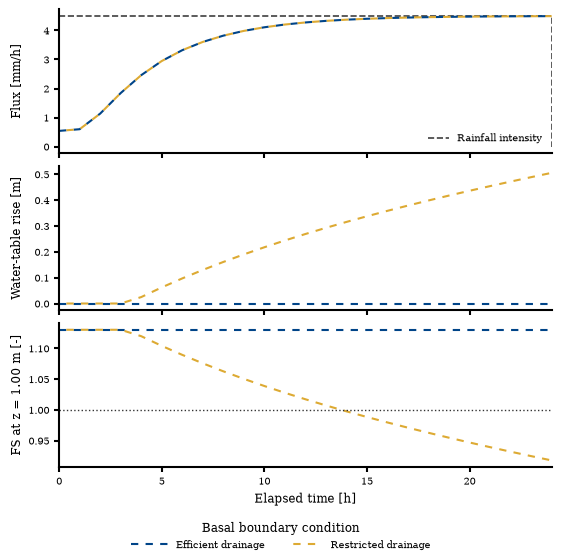

In [3]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(5.5, 5.5), constrained_layout=True)
line_colors = {"Efficient drainage": COLORS.blue, "Restricted drainage": COLORS.yellow}
line_styles = {
    "Efficient drainage": (0, (3.5, 3.5)),  # complementary dash phase, no data offset
    "Restricted drainage": (3.5, (3.5, 3.5)),  # complementary dash phase, no data offset
}

reference = results["Restricted drainage"]
t_h = reference.time
axes[0].step(
    t_h, reference.rainfall_flux * 3.6e6, where="post",  # convert m/s to mm/h
    color="0.25", linestyle="--", linewidth=1.2, label="Rainfall intensity",
)
for name, result in results.items():
    color = line_colors[name]
    style = {"color": color, "linestyle": line_styles[name], "linewidth": 1.5}
    axes[0].plot(t_h, result.basal_flux * 3.6e6, **style)  # convert m/s to mm/h
    axes[1].plot(t_h, result.water_table_rise, **style)
    axes[2].plot(t_h, result.factor_of_safety_at_failure_plane, **style, label=name)

axes[0].set_ylabel("Flux [mm/h]")
axes[1].set_ylabel("Water-table rise [m]")
axes[2].set_ylabel(f"FS at z = {selected_depth_m:.2f} m [-]")
axes[2].set_xlabel("Elapsed time [h]")
axes[2].axhline(1.0, color="0.2", linestyle=":", linewidth=1.0)
for ax in axes:
    ax.set_xlim(0.0, duration_h)
axes[0].legend(loc="lower right", ncol=1)
handles, labels = axes[-1].get_legend_handles_labels()
fig.align_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, title="Basal boundary condition", handlelength=3.5)
plt.show()


## Read the complete vertical profiles

Each row below is one drainage assumption, identified by a single row title; each column is one state variable. The horizontal axis is shared across the two rows in each column, allowing direct comparison on the same scale. Curves show 0, 10, 14, 18, and 24 h. Depth increases downward. The horizontal dashed line marks the selected failure plane, and the dotted vertical line in the factor-of-safety panels marks $\mathrm{FS}=1$.

Plotting the profiles makes an important distinction visible: a time series evaluated only at the failure plane cannot show how the response varies with depth. Here, the profile arrays include pressure head and factor of safety at every model depth.

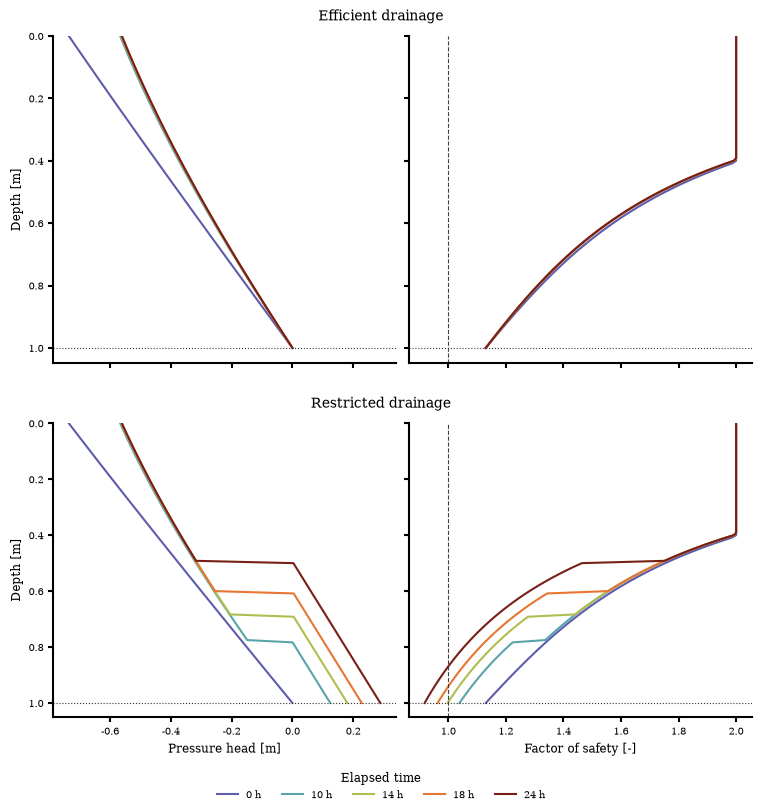

In [4]:
selected_hours = np.array([0.0, 10.0, 14.0, 18.0, 24.0])
selected_colors = TIME_CMAP(np.linspace(0.05, 0.95, len(selected_hours)))
fig = plt.figure(figsize=(7.5, 8.0), constrained_layout=True)
row_figures = fig.subfigures(2, 1, hspace=0.05)
axes = np.empty((2, 2), dtype=object)

for row, ((name, result), row_figure) in enumerate(zip(results.items(), row_figures)):
    axes[row] = row_figure.subplots(1, 2, sharey=True)
    row_figure.suptitle(name, fontsize=10)
    if row > 0:
        for col in range(2):
            axes[row, col].sharex(axes[0, col])
    arrays = result.arrays()
    model_time_h = result.time
    for color, target_h in zip(selected_colors, selected_hours):
        idx = int(np.argmin(np.abs(model_time_h - target_h)))
        label = f"{model_time_h[idx]:g} h"
        axes[row, 0].plot(arrays["pressure_head_total"][idx], arrays["z"], color=color, label=label)
        axes[row, 1].plot(arrays["factor_of_safety"][idx], arrays["z"], color=color, label=label)
    axes[row, 0].set_ylabel("Depth [m]")
    for ax in axes[row]:
        ax.set_ylim(hydro.initial_water_table_depth + 0.05, 0.0)
        ax.axhline(selected_depth_m, color="0.2", linestyle=":", linewidth=0.8)
    axes[row, 1].axvline(1.0, color="0.25", linestyle="--", linewidth=0.8)

for ax in axes[0]:
    ax.tick_params(axis="x", labelbottom=False)
axes[1, 0].set_xlabel("Pressure head [m]")
axes[1, 1].set_xlabel("Factor of safety [-]")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5, title="Elapsed time")
plt.show()


## Same rainfall total, two peaks

Keep the soil, initial state, strength, equation set, and both drainage assumptions unchanged. Use the following successive rainfall intensities $I$ and interval durations $d$. Here rainfall stays below saturated conductivity, so each rainfall rate is also the effective infiltration rate.

| Intensity $I$ [mm/h] | Duration $d$ [h] |
| ---: | ---: |
| 0 | 3 |
| 3.5 | 2 |
| 6 | 1 |
| 10 | 1 |
| 13 | 0.5 |
| 9 | 1 |
| 5 | 2 |
| 3.5 | 4 |
| 1.5 | 2 |
| 4 | 2.5 |
| 6.5 | 1 |
| 10 | 1 |
| 7.5 | 2 |
| 1 | 1 |

The durations sum to 24 h. Multiplying each intensity by its duration and adding the interval amounts gives 108 mm, exactly the same as uniform rain at 4.5 mm/h for 24 h. The first peak is 13 mm/h at 7–7.5 h; the second is 10 mm/h at 20–21 h. The intervening lower rates separate two periods of increasing and decreasing intensity.

Supply these intervals directly, without smoothing or rescaling. Every rate remains below saturated conductivity, so the histories have the same effective infiltration as well as the same gross rainfall total. This isolates rainfall timing from input discarded by the infiltration cap.

Rerun both histories on the same 15-minute output grid, with a five-minute maximum storage integration interval. The solver also inserts rainfall breakpoints into the integration grid. See [numerical controls](/unsatstab/inputs-outputs/#numerical-controls) for convergence checks.


,Rainfall history,Total rainfall [mm],Effective infiltration [mm]
0,Uniform,108.0,108.0
1,Two peaks,108.0,108.0


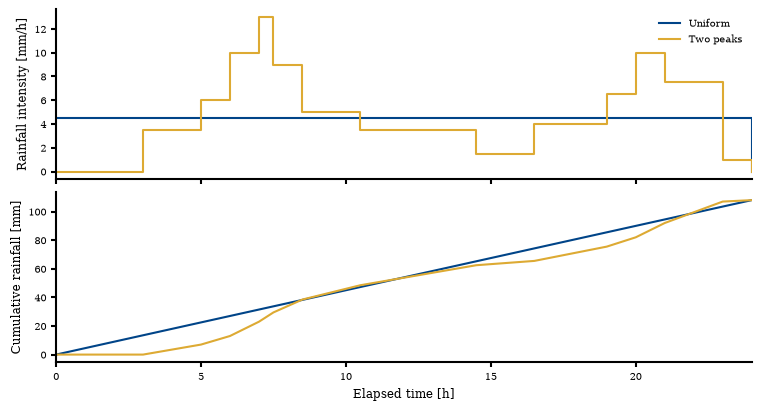

In [5]:
import pandas as pd

interval_durations_h = np.array(
    [3.0, 2.0, 1.0, 1.0, 0.5, 1.0, 2.0, 4.0, 2.0, 2.5, 1.0, 1.0, 2.0, 1.0]
)
peak_rates_mm_h = np.array(
    [0.0, 3.5, 6.0, 10.0, 13.0, 9.0, 5.0, 3.5, 1.5, 4.0, 6.5, 10.0, 7.5, 1.0]
)
breakpoints_h = np.r_[0.0, np.cumsum(interval_durations_h)]
assert np.isclose(breakpoints_h[-1], duration_h)
assert np.isclose(np.dot(interval_durations_h, peak_rates_mm_h), 108.0)
peaked_rainfall = us.RainfallSeries(
    breakpoints=breakpoints_h,  # hours
    fluxes=peak_rates_mm_h / 3.6e6,  # convert mm/h to m/s
)
rainfall_histories = {"Uniform": rainfall, "Two peaks": peaked_rainfall}
comparison_output_times_h = np.arange(97, dtype=float) * (15.0 / 60.0)  # convert minutes to hours
comparison_results = {}
amount_rows = []
for history_name, forcing in rainfall_histories.items():
    rainfall_total_mm = np.dot(np.diff(forcing.breakpoints), forcing.fluxes) * 3.6e6  # convert hours to seconds and water metres to mm
    effective_total_mm = np.dot(
        np.diff(forcing.breakpoints),
        np.minimum(forcing.fluxes, hydro.saturated_hydraulic_conductivity),
    ) * 3.6e6  # convert hours to seconds and water metres to mm
    assert np.isclose(rainfall_total_mm, 108.0)
    assert np.isclose(effective_total_mm, rainfall_total_mm)
    amount_rows.append({
        "Rainfall history": history_name,
        "Total rainfall [mm]": rainfall_total_mm,
        "Effective infiltration [mm]": effective_total_mm,
    })
    for boundary_name, boundary in boundaries.items():
        comparison_results[(history_name, boundary_name)] = us.run_single_column(
            hydro=hydro,
            rainfall=forcing,
            strength=strength,
            boundary=boundary,
            depth_to_failure_plane=selected_depth_m,
            output_times=comparison_output_times_h,
            storage_time_step=5.0 / 60.0,  # convert minutes to hours
        )
display(pd.DataFrame(amount_rows))

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(7.5, 4.0), constrained_layout=True)
history_colors = {"Uniform": COLORS.blue, "Two peaks": COLORS.yellow}
for name, forcing in rainfall_histories.items():
    cumulative_mm = np.r_[0.0, np.cumsum(np.diff(forcing.breakpoints) * forcing.fluxes)] * 3.6e6  # convert hours to seconds and water metres to mm
    axes[0].step(forcing.breakpoints, np.r_[forcing.fluxes * 3.6e6, 0.0],  # convert m/s to mm/h; seconds to hours
                 where="post", color=history_colors[name], label=name)
    axes[1].plot(forcing.breakpoints, cumulative_mm,
                 color=history_colors[name], label=name)
axes[0].set_ylabel("Rainfall intensity [mm/h]")
axes[0].legend()
axes[1].set(xlabel="Elapsed time [h]", ylabel="Cumulative rainfall [mm]", xlim=(0, 24))
plt.show()


## Compare the two rainfall histories

Each column below uses one basal drainage assumption. Colors identify rainfall history. Compare the timing and magnitude of basal flux, water-table rise, and FS; equal rainfall totals do not require identical intermediate states. The [superposition of infiltration changes](/unsatstab/fundamentals/#response-to-changing-rainfall) explains why each peak has its own delayed response.

The summary reports extrema over the sampled 0–24 h window and the first sampled FS at or below 1. A missing crossing means none was sampled in that window. It does not exclude a later response after rainfall ends.

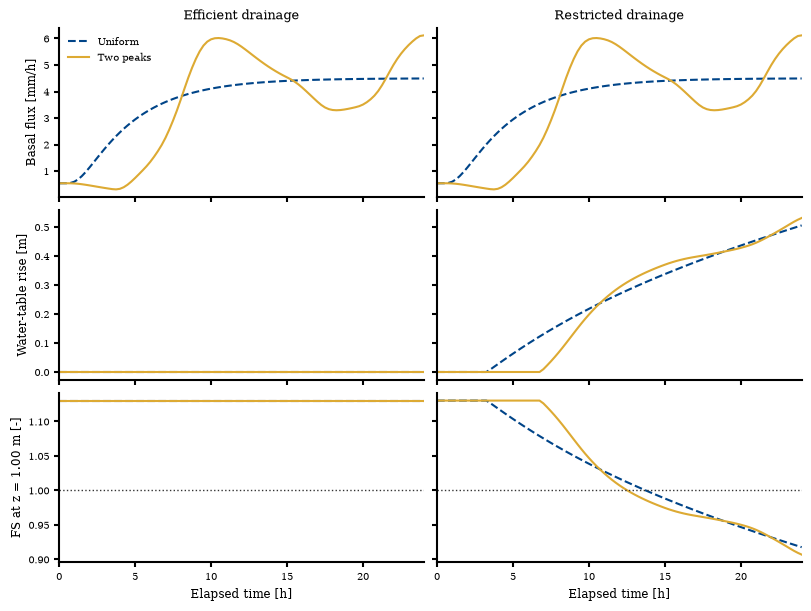

,Boundary,Rainfall history,Maximum basal flux [mm/h],Maximum water-table rise [m],Minimum plane FS,First sampled FS <= 1 [h]
0,Efficient drainage,Uniform,4.4918,0.0000,1.1303,NaN
1,Efficient drainage,Two peaks,6.1175,0.0000,1.1303,NaN
2,Restricted drainage,Uniform,4.4918,0.5057,0.9176,13.75
3,Restricted drainage,Two peaks,6.1175,0.5313,0.9069,12.75


In [6]:
fig, axes = plt.subplots(3, 2, sharex=True, sharey="row", figsize=(8.0, 6.0), constrained_layout=True)
comparison_rows = []
for col, boundary_name in enumerate(boundaries):
    axes[0, col].set_title(boundary_name)
    for history_name in rainfall_histories:
        result = comparison_results[(history_name, boundary_name)]
        time_h = result.time
        style = {"color": history_colors[history_name],
                 "linestyle": "--" if history_name == "Uniform" else "-", "linewidth": 1.5}
        axes[0, col].plot(time_h, result.basal_flux * 3.6e6, label=history_name, **style)  # convert m/s to mm/h
        axes[1, col].plot(time_h, result.water_table_rise, **style)
        axes[2, col].plot(time_h, result.factor_of_safety_at_failure_plane, **style)
        crossings = np.flatnonzero(result.factor_of_safety_at_failure_plane <= 1.0)
        comparison_rows.append({
            "Boundary": boundary_name,
            "Rainfall history": history_name,
            "Maximum basal flux [mm/h]": result.basal_flux.max() * 3.6e6,  # convert m/s to mm/h
            "Maximum water-table rise [m]": result.water_table_rise.max(),
            "Minimum plane FS": result.factor_of_safety_at_failure_plane.min(),
            "First sampled FS <= 1 [h]": time_h[crossings[0]] if crossings.size else np.nan,
        })
    axes[2, col].axhline(1.0, color="0.2", linestyle=":", linewidth=1.0)
    axes[2, col].set(xlabel="Elapsed time [h]", xlim=(0, 24))
axes[0, 0].set_ylabel("Basal flux [mm/h]")
axes[1, 0].set_ylabel("Water-table rise [m]")
axes[2, 0].set_ylabel(f"FS at z = {selected_depth_m:.2f} m [-]")
axes[0, 0].legend()
plt.show()
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))


## Vertical profiles during and after the peaks

Repeat the depth-profile exercise for the two-peak history at 0, 10, 12, 18, and 24 h. These snapshots sample the lower-input period and the later increase and recession. Colors denote time; rows denote drainage assumptions. The horizontal guide marks the failure plane at 1.00 m.

Compare these profiles with the uniform-rainfall profiles above, especially suction changes above the initial water table and the positive-pressure and FS responses at the selected plane. The [pressure assumptions](/unsatstab/fundamentals/#basal-and-pressure-assumptions) still apply: an abrupt join near the estimated water table reflects the reconstruction, rather than a resolved wetting front.

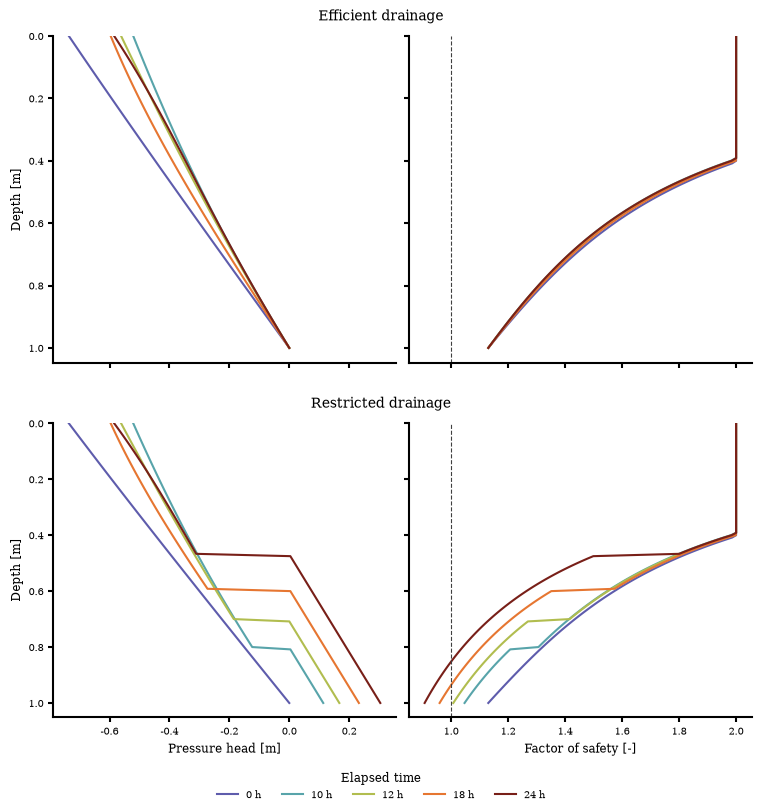

In [7]:
peak_profile_hours = np.array([0.0, 10.0, 12.0, 18.0, 24.0])
peak_profile_colors = TIME_CMAP(np.linspace(0.05, 0.95, len(peak_profile_hours)))
fig = plt.figure(figsize=(7.5, 8.0), constrained_layout=True)
row_figures = fig.subfigures(2, 1, hspace=0.05)
axes = np.empty((2, 2), dtype=object)

for row, (boundary_name, row_figure) in enumerate(zip(boundaries, row_figures)):
    axes[row] = row_figure.subplots(1, 2, sharey=True)
    row_figure.suptitle(boundary_name, fontsize=10)
    if row > 0:
        for col in range(2):
            axes[row, col].sharex(axes[0, col])
    result = comparison_results[("Two peaks", boundary_name)]
    arrays = result.arrays()
    for target_h, color in zip(peak_profile_hours, peak_profile_colors):
        idx = int(np.argmin(np.abs(result.time - target_h)))
        axes[row, 0].plot(arrays["pressure_head_total"][idx], arrays["z"], color=color, label=f"{target_h:g} h")
        axes[row, 1].plot(arrays["factor_of_safety"][idx], arrays["z"], color=color)
    axes[row, 0].set_ylabel("Depth [m]")
    axes[row, 1].axvline(1.0, color="0.25", linestyle="--", linewidth=0.8)
    for ax in axes[row]:
        ax.set_ylim(hydro.initial_water_table_depth + 0.05, 0.0)
for ax in axes[0]:
    ax.tick_params(axis="x", labelbottom=False)
axes[1, 0].set_xlabel("Pressure head [m]")
axes[1, 1].set_xlabel("Factor of safety [-]")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=5, title="Elapsed time")
plt.show()


## What changes when rainfall is concentrated

The failure plane starts at the water table, with zero pressure head. Estimated rise therefore increases pressure at that plane without first requiring the water table to cross an initially unsaturated gap.

With restricted drainage, maximum estimated rise within 24 h is 0.506 m under uniform rain and 0.531 m under the tabulated two-peak history. Minimum plane FS is 0.918 and 0.907, respectively. The first sampled FS ≤ 1 occurs at 13.75 h under uniform rain and 12.75 h under the two-peak history. These are 15-minute sampled crossings, not continuous failure times.

Efficient drainage produces no retained-water rise in either case. The selected plane stays at the water table, so its reconstructed pressure head remains zero and its FS remains at the initial value. Unsaturated profiles above it can still respond to rainfall. Peak basal transfer stays below this boundary's capacity.

Equal rainfall totals do not determine the response by themselves: input timing, delayed basal transfer, and storage matter. These outcomes concern the specified soil, equation set, initial water table, and 24-hour window.
